In [53]:
import numpy as np
from scipy.optimize import minimize

# ==========================================
# HAWKES PARAMETER ESTIMATION (Appendix C.1.1)
# ==========================================
def hawkes_log_likelihood(params, events_m, events_n, T):
    """
    Computes the log-likelihood for dimension 'm' excited by dimension 'n'.
    Uses Ozaki's recursive formulation (Eq C.23 and C.24).
    params: [lambda_m0, alpha_mn, beta_mn]
    """
    lambda_m0, alpha_mn, beta_mn = params
    
    # Enforce strict positivity for stability
    if lambda_m0 <= 0 or alpha_mn <= 0 or beta_mn <= 0 or alpha_mn >= beta_mn:
        return 1e9 
    
    # 1. Integrated Intensity (Eq C.27)
    integrated_intensity = lambda_m0 * T
    for t_k in events_n:
        if t_k <= T:
            integrated_intensity += (alpha_mn / beta_mn) * (1 - np.exp(-beta_mn * (T - t_k)))
            
    # 2. Recursive Summation R_{mn}(l) (Eq C.23)
    log_lambda_sum = 0.0
    R_mn = 0.0
    
    n_idx = 0
    N_n = len(events_n)
    
    is_self_exciting = (events_m is events_n)
    
    for l in range(len(events_m)):
        t_l = events_m[l]
        if t_l > T: break
            
        if l == 0:
            if is_self_exciting:
                R_mn = 0.0
            else:
                # Sum over all events in n that occurred before the first event in m
                while n_idx < N_n and events_n[n_idx] < t_l:
                    R_mn += np.exp(-beta_mn * (t_l - events_n[n_idx]))
                    n_idx += 1
        else:
            t_prev = events_m[l-1]
            decay = np.exp(-beta_mn * (t_l - t_prev))
            
            if is_self_exciting:
                R_mn = decay * (1 + R_mn)
            else:
                R_mn = decay * R_mn
                while n_idx < N_n and events_n[n_idx] < t_l:
                    R_mn += np.exp(-beta_mn * (t_l - events_n[n_idx]))
                    n_idx += 1
                    
        # Intensity at time t_l
        lambda_current = lambda_m0 + alpha_mn * R_mn
        log_lambda_sum += np.log(lambda_current)
        
    # Log-Likelihood (Eq C.24)
    # Note: We return the negative log-likelihood for minimization
    return -(log_lambda_sum - integrated_intensity)

def fit_hawkes_1D(event_times, T):
    """Calibrates a 1D Hawkes process using the recursive MLE."""
    initial_guess = [len(event_times)/T * 0.5, 0.1, 1.0] # [mu, alpha, beta]
    bounds = [(1e-5, None), (1e-5, None), (1e-5, None)]
    
    res = minimize(hawkes_log_likelihood, initial_guess, args=(event_times, event_times, T),
                   bounds=bounds, method='L-BFGS-B')
    return res.x # Returns [lambda0, alpha, beta]

# --- POISSON PARAMETER ESTIMATION ---
def fit_poisson(event_times, T):
    """Simple count estimator for Poisson order flows."""
    return len(event_times) / T

In [55]:
# ==========================================
# ALGORITHM 1: POISSON ORDER FLOWS (Sec 9.2.1)
# ==========================================
def simulate_lob_algorithm_1(K, lambda_M, lambda_L_vec, lambda_C_vec, a_inf, b_inf, N_events):
    """
    Algorithm 1: Order book simulation with Poisson order flows.
    Assumes symmetric bid/ask parameters for simplicity as stated in the book.
    """
    # 1: Initialization
    t = 0.0
    a = np.zeros(K) # Ask limits
    b = np.zeros(K) # Bid limits
    
    Lambda_L = np.sum(lambda_L_vec)
    
    times, spreads = [], []
    
    # 2: for n = 1,...,N
    for _ in range(N_events):
        # 3: Update cancellation intensities
        Lambda_C_a = np.sum(lambda_C_vec * a)
        Lambda_C_b = np.sum(lambda_C_vec * np.abs(b))
        
        # 4: Time of next event
        Lambda_total = 2 * (lambda_M + Lambda_L) + Lambda_C_a + Lambda_C_b
        if Lambda_total == 0: 
            break
            
        tau = np.random.exponential(1.0 / Lambda_total)
        t += tau
        
        # 5: Type of next event
        probs = np.array([
            lambda_M, lambda_M,            # Market Buy, Market Sell
            Lambda_L, Lambda_L,            # Limit Buy, Limit Sell
            Lambda_C_a, Lambda_C_b         # Cancel Ask, Cancel Bid
        ]) / Lambda_total
        
        event_type = np.random.choice(6, p=probs)
        
        # 6: Volume of next event (Using unit size = 1 for simplicity here)
        q = 1.0 
        
        # 7-14: Price of next event and Update Book
        if event_type == 0: # Market Buy
            for i in range(K):
                if a[i] > 0:
                    a[i] = max(0, a[i] - q)
                    break
        elif event_type == 1: # Market Sell
            for i in range(K):
                if b[i] < 0: # Bids are negative convention
                    b[i] = min(0, b[i] + q)
                    break
        elif event_type == 2: # Limit Buy
            lvl = np.random.choice(K, p=lambda_L_vec/Lambda_L)
            b[lvl] -= q 
        elif event_type == 3: # Limit Sell
            lvl = np.random.choice(K, p=lambda_L_vec/Lambda_L)
            a[lvl] += q
        elif event_type == 4: # Cancel Ask
            # Draw relative level weighted by available volume
            p_c = (lambda_C_vec * a) / Lambda_C_a
            lvl = np.random.choice(K, p=p_c)
            a[lvl] = max(0, a[lvl] - q)
        elif event_type == 5: # Cancel Bid
            p_c = (lambda_C_vec * np.abs(b)) / Lambda_C_b
            lvl = np.random.choice(K, p=p_c)
            b[lvl] = min(0, b[lvl] + q)
            
        # 15: Enforce boundary conditions
        # (Implicitly handled if arrays are fixed size, assuming hidden liquidity replenishes)
        if np.sum(a) == 0: a[-1] = a_inf
        if np.sum(np.abs(b)) == 0: b[-1] = b_inf
            
        times.append(t)
        
    return times, a, b

In [57]:
# ==========================================
# ALGORITHM 2: HAWKES THINNING (Sec 9.3.2)
# ==========================================
def simulate_hawkes_algorithm_2(lambda_0, alpha, beta, T):
    """
    Algorithm 2: Generic thinning algorithm for the simulation of a multivariate Hawkes process.
    Based on Lewis and Shedler (1979).
    """
    P = len(lambda_0) # Number of dimensions
    
    # 1: Initialization
    history = [[] for _ in range(P)]
    
    # I* is the bounding intensity
    I_star = np.sum(lambda_0)
    s = 0.0
    
    # 2: Time of first event
    s += np.random.exponential(1.0 / I_star)
    
    # 3: while s < T
    while s < T:
        # Calculate exact intensities at time s
        lambdas = np.copy(lambda_0)
        for m in range(P):
            for n in range(P):
                excitation = 0.0
                for t_k in history[n]:
                    excitation += alpha[m, n] * np.exp(-beta[m, n] * (s - t_k))
                lambdas[m] += excitation
                
        I_P = np.sum(lambdas)
        
        # 4: Draw D uniformly distributed
        D = np.random.uniform(0, 1)
        
        # 5: if D <= I_P(s) / I*
        if D <= I_P / I_star:
            # 6-8: Determine which event type n0 occurred
            cumulative_probs = np.cumsum(lambdas) / I_P
            n0 = np.searchsorted(cumulative_probs, np.random.uniform(0, 1))
            history[n0].append(s)
            
            # 9: Update maximum intensity with the jumps triggered by event n0
            I_star = I_P + np.sum(alpha[:, n0])
        else:
            # Event rejected, upper bound tightened to exact intensity
            I_star = I_P
            
        # 10: Time of next potential event
        s += np.random.exponential(1.0 / I_star)
        
    return history

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wasserstein_distance

# ==========================================
# 1. UPGRADED TEXTBOOK ALGORITHMS (WITH SNAPSHOTS)
# ==========================================

def simulate_lob_algorithm_1_snapshots(K, lambda_M, lambda_L_vec, lambda_C_vec, a_inf, b_inf, max_time=500.0, dt=10.0):
    """
    Algorithm 1 (Poisson) adapted to record LOB snapshots every dt seconds.
    """
    t = 0.0
    # Initialize queues with some volume
    a = np.array([500.0] * K)
    b = np.array([-500.0] * K) # Bids are negative convention
    
    Lambda_L = np.sum(lambda_L_vec)
    
    snapshots_a, snapshots_b = [], []
    current_time = 0.0
    
    while t < max_time:
        # Record snapshot if we cross a dt boundary
        while t >= current_time:
            snapshots_a.append(a.copy())
            snapshots_b.append(b.copy())
            current_time += dt
            
        Lambda_C_a = np.sum(lambda_C_vec * a)
        Lambda_C_b = np.sum(lambda_C_vec * np.abs(b))
        
        Lambda_total = 2 * (lambda_M + Lambda_L) + Lambda_C_a + Lambda_C_b
        if Lambda_total == 0: break
            
        t += np.random.exponential(1.0 / Lambda_total)
        
        probs = np.array([lambda_M, lambda_M, Lambda_L, Lambda_L, Lambda_C_a, Lambda_C_b]) / Lambda_total
        event_type = np.random.choice(6, p=probs)
        q = 100.0 # Lot size
        
        if event_type == 0: # Market Buy (hits Ask)
            for i in range(K):
                if a[i] > 0:
                    a[i] = max(0, a[i] - q)
                    break
        elif event_type == 1: # Market Sell (hits Bid)
            for i in range(K):
                if b[i] < 0: 
                    b[i] = min(0, b[i] + q)
                    break
        elif event_type == 2: # Limit Buy
            lvl = np.random.choice(K, p=lambda_L_vec/Lambda_L)
            b[lvl] -= q 
        elif event_type == 3: # Limit Sell
            lvl = np.random.choice(K, p=lambda_L_vec/Lambda_L)
            a[lvl] += q
        elif event_type == 4: # Cancel Ask
            p_c = (lambda_C_vec * a) / Lambda_C_a if Lambda_C_a > 0 else np.ones(K)/K
            lvl = np.random.choice(K, p=p_c)
            a[lvl] = max(0, a[lvl] - q)
        elif event_type == 5: # Cancel Bid
            p_c = (lambda_C_vec * np.abs(b)) / Lambda_C_b if Lambda_C_b > 0 else np.ones(K)/K
            lvl = np.random.choice(K, p=p_c)
            b[lvl] = min(0, b[lvl] + q)
            
    return np.array(snapshots_a), np.array(snapshots_b)

def reconstruct_hawkes_snapshots(hawkes_history, max_time=500.0, dt=10.0, K=3):
    """
    Converts Algorithm 2 (Hawkes Thinning) event history back into LOB snapshots.
    Dimensions: [MO_buy, MO_sell, LO_buy, LO_sell, CA_ask, CA_bid]
    """
    # Flatten and sort events: (time, event_type)
    events = []
    for event_type, times in enumerate(hawkes_history):
        for t in times:
            events.append((t, event_type))
    events.sort(key=lambda x: x[0])
    
    a = np.array([500.0] * K)
    b = np.array([-500.0] * K)
    snapshots_a, snapshots_b = [], []
    current_time = 0.0
    q = 100.0
    
    for t, event_type in events:
        while t >= current_time:
            snapshots_a.append(a.copy())
            snapshots_b.append(b.copy())
            current_time += dt
            if current_time > max_time: break
        
        # Approximate multi-level distribution
        lvl = np.random.choice(K, p=[0.6, 0.3, 0.1]) 
        
        if event_type == 0:
            for i in range(K):
                if a[i] > 0: a[i] = max(0, a[i] - q); break
        elif event_type == 1:
            for i in range(K):
                if b[i] < 0: b[i] = min(0, b[i] + q); break
        elif event_type == 2: b[lvl] -= q
        elif event_type == 3: a[lvl] += q
        elif event_type == 4: a[lvl] = max(0, a[lvl] - q)
        elif event_type == 5: b[lvl] = min(0, b[lvl] + q)
            
    return np.array(snapshots_a), np.array(snapshots_b)

# ==========================================
# 2. RUN SIMULATIONS & FORMAT TO 6 LEVELS
# ==========================================
print("Running Poisson Simulation (Algorithm 1)...")
# Parameters (Approximated to match MSFT liquidity)
K = 3
p_ask_snaps, p_bid_snaps = simulate_lob_algorithm_1_snapshots(
    K=3, lambda_M=0.5, 
    lambda_L_vec=np.array([1.5, 1.0, 0.5]), 
    lambda_C_vec=np.array([0.01, 0.01, 0.01]), 
    a_inf=1000, b_inf=-1000, max_time=500.0
)

print("Running Hawkes Simulation (Algorithm 2)...")
# Using the Hawkes simulation provided in the previous step
D = 6
lambda_0 = np.array([0.5, 0.5, 1.5, 1.5, 0.5, 0.5])
alpha = np.ones((D, D)) * 0.05
np.fill_diagonal(alpha, 0.1)
beta = np.ones((D, D)) * 10.0

# Using simulate_hawkes_algorithm_2 from the previous response
h_history = simulate_hawkes_algorithm_2(lambda_0, alpha, beta, T=500.0)
h_ask_snaps, h_bid_snaps = reconstruct_hawkes_snapshots(h_history, K=3, max_time=500.0)

# Build (N, 6) arrays
def format_to_6_levels(ask_snaps, bid_snaps):
    N = len(ask_snaps)
    arr = np.zeros((N, 6))
    # Bids (Indices 0,1,2 = Bid3, Bid2, Bid1) Note: Bid arrays are [L1, L2, L3]
    arr[:, 2] = bid_snaps[:, 0]
    arr[:, 1] = bid_snaps[:, 1]
    arr[:, 0] = bid_snaps[:, 2]
    # Asks (Indices 3,4,5 = Ask1, Ask2, Ask3)
    arr[:, 3] = ask_snaps[:, 0]
    arr[:, 4] = ask_snaps[:, 1]
    arr[:, 5] = ask_snaps[:, 2]
    return arr

sim_poisson = format_to_6_levels(p_ask_snaps, p_bid_snaps)
sim_hawkes = format_to_6_levels(h_ask_snaps, h_bid_snaps)

# Normalization: Q_tilde = sign(Q) * sqrt(|Q|) / c
NORMALIZATION_CONSTANT = 100.0
sim_poisson_norm = np.sign(sim_poisson) * np.sqrt(np.abs(sim_poisson)) / NORMALIZATION_CONSTANT
sim_hawkes_norm = np.sign(sim_hawkes) * np.sqrt(np.abs(sim_hawkes)) / NORMALIZATION_CONSTANT

# ==========================================
# 3. PLOTTING FUNCTION
# ==========================================
def plot_benchmark(real_data, sim_data, model_name):
    min_len = min(len(real_data), len(sim_data))
    real_data, sim_data = real_data[:min_len], sim_data[:min_len]

    level_indices = {'Ask 1': 3, 'Bid 1': 2, 'Ask 2': 4, 'Bid 2': 1, 'Ask 3': 5, 'Bid 3': 0}
    plot_order = ['Ask 1', 'Bid 1', 'Ask 2', 'Bid 2', 'Ask 3', 'Bid 3']
    
    # --- A. Marginal Densities (KDE) ---
    fig_kde, axes = plt.subplots(3, 2, figsize=(14, 10))
    axes = axes.flatten()
    
    for i, level_name in enumerate(plot_order):
        idx = level_indices[level_name]
        real_lvl, sim_lvl = real_data[:, idx], sim_data[:, idx]
        
        # Calculate W1 on denormalized data
        w1_dist = wasserstein_distance(real_lvl, sim_lvl)
        
        sns.kdeplot(real_lvl, ax=axes[i], fill=True, color="steelblue", label="Real", alpha=0.5)
        sns.kdeplot(sim_lvl, ax=axes[i], fill=True, color="darkorange", label="Fake", alpha=0.5)
        
        axes[i].axvline(0, color='black', linestyle='-', linewidth=1)
        axes[i].set_title(f"{level_name}, W1: {w1_dist:.3f}")
        axes[i].set_ylabel("Density")
        axes[i].legend()
        
    plt.tight_layout()
    plt.suptitle(f"Marginal Distributions (Textbook {model_name})", y=1.02, fontsize=16)
    plt.show()

    # --- B. Average LOB Shape ---
    real_denorm = np.sign(real_data) * (np.abs(real_data) * NORMALIZATION_CONSTANT)**2
    sim_denorm = np.sign(sim_data) * (np.abs(sim_data) * NORMALIZATION_CONSTANT)**2

    mean_real, mean_sim = real_denorm.mean(axis=0), sim_denorm.mean(axis=0)
    
    ordered_indices = [0, 1, 2, 3, 4, 5]
    labels = ['Bid 3', 'Bid 2', 'Bid 1', 'Ask 1', 'Ask 2', 'Ask 3']
    
    ordered_mean_real = [mean_real[i] for i in ordered_indices]
    ordered_mean_sim = [mean_sim[i] for i in ordered_indices]

    x = np.arange(len(labels))
    width = 0.35
    
    fig_bar, ax_bar = plt.subplots(figsize=(10, 6))
    ax_bar.bar(x - width/2, ordered_mean_real, width, label='Real', color='steelblue')
    ax_bar.bar(x + width/2, ordered_mean_sim, width, label='Fake', color='darkorange')

    ax_bar.set_ylabel('Quantity (Standardized Queue Size)')
    ax_bar.set_title(f'Average LOB Shape (Textbook {model_name})')
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(labels)
    ax_bar.legend()
    plt.tight_layout()
    plt.show()

Running Poisson Simulation (Algorithm 1)...
Running Hawkes Simulation (Algorithm 2)...
Generating plots...


In [61]:
MESSAGE_FILE = "MSFT_2012-06-21_34200000_57600000_message_10.csv"
ORDERBOOK_FILE = "MSFT_2012-06-21_34200000_57600000_orderbook_10.csv"

# 1. Load data
msg_cols = ['Time', 'Type', 'OrderID', 'Size', 'Price', 'Direction']
messages = pd.read_csv(MESSAGE_FILE, names=msg_cols)

ob_cols = []
for i in range(1, 11): 
    ob_cols.extend([f'AskPrice{i}', f'AskSize{i}', f'BidPrice{i}', f'BidSize{i}'])
orderbook = pd.read_csv(ORDERBOOK_FILE, names=ob_cols)

# Combine time with orderbook and filter to trading hours
df = pd.concat([messages[['Time']], orderbook], axis=1)
df = df[(df['Time'] >= 36000) & (df['Time'] <= 55800)]

# 2. Sample at 10-second intervals
df['TimeBin'] = (df['Time'] // 10.0) * 10.0
sampled_df = df.drop_duplicates(subset=['TimeBin'], keep='last').copy()

# 3. Extract the 6 levels: [Bid3, Bid2, Bid1, Ask1, Ask2, Ask3]
# Remember: Bids are made negative, Asks remain positive
state_vectors = []
for _, row in sampled_df.iterrows():
    bids = [-row['BidSize3'], -row['BidSize2'], -row['BidSize1']]
    asks = [row['AskSize1'], row['AskSize2'], row['AskSize3']]
    state_vectors.append(bids + asks)
    
full_real_data = np.array(state_vectors)

# 4. Take the test split (the last 20% of the day) just like the GAN did
split_idx = int(len(full_real_data) * 0.8)

# We use the raw target states (X_next) for the test set
# Since pairs were (S_t, X_{t+dt}), the targets are from index 1 onwards
X_next_full = full_real_data[1:]
real_X = X_next_full[split_idx:]

print(f"Successfully loaded real_X with shape: {real_X.shape}")

Successfully loaded real_X with shape: (395, 6)


Generating plots...


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

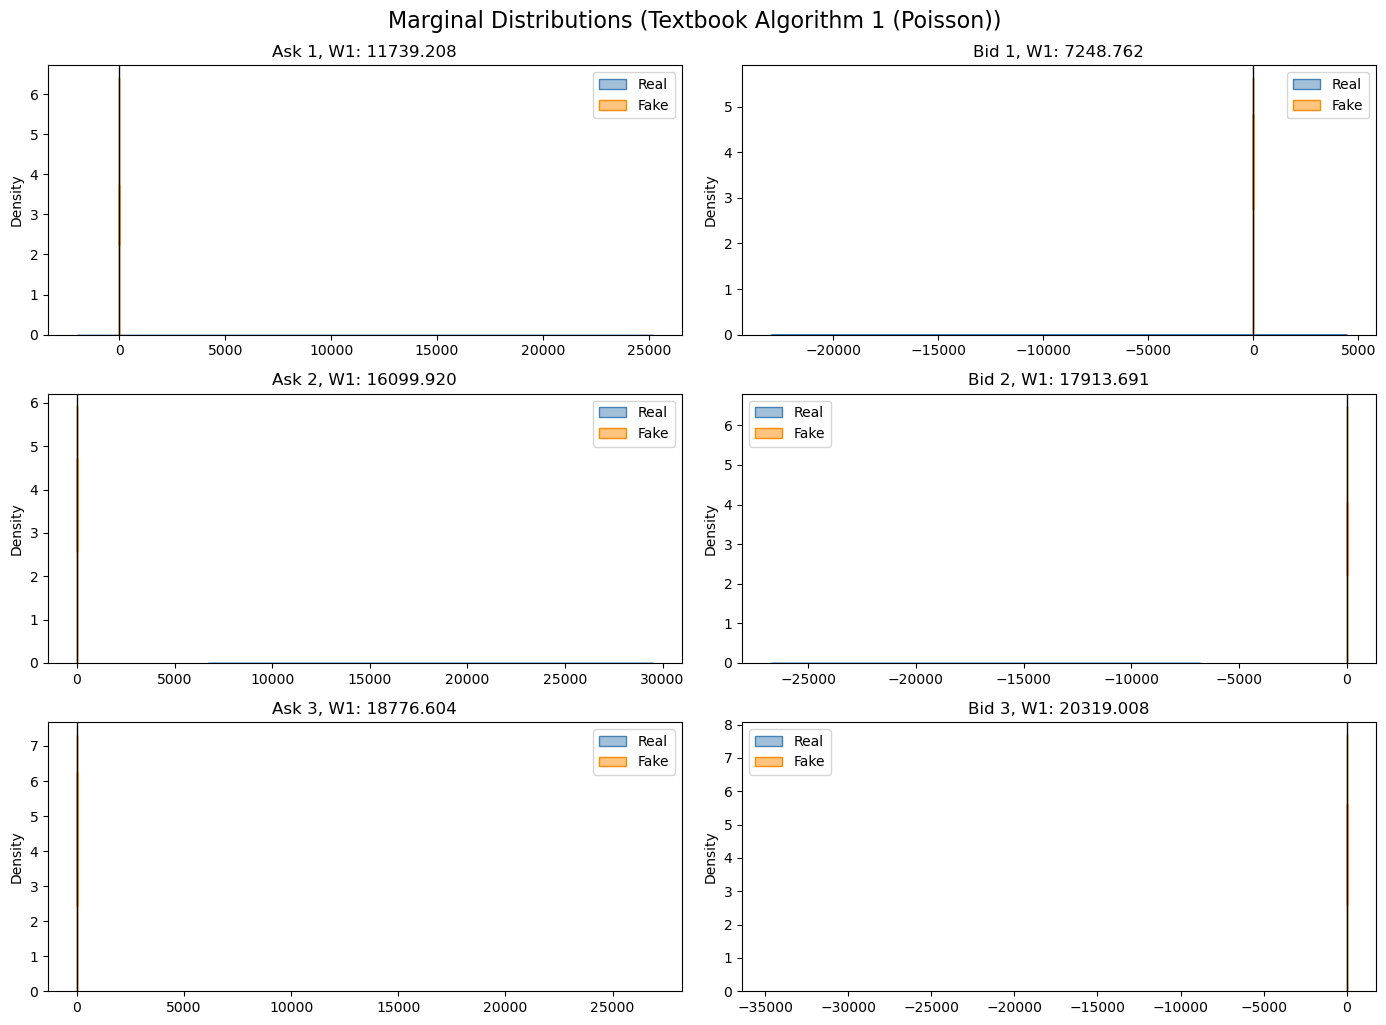

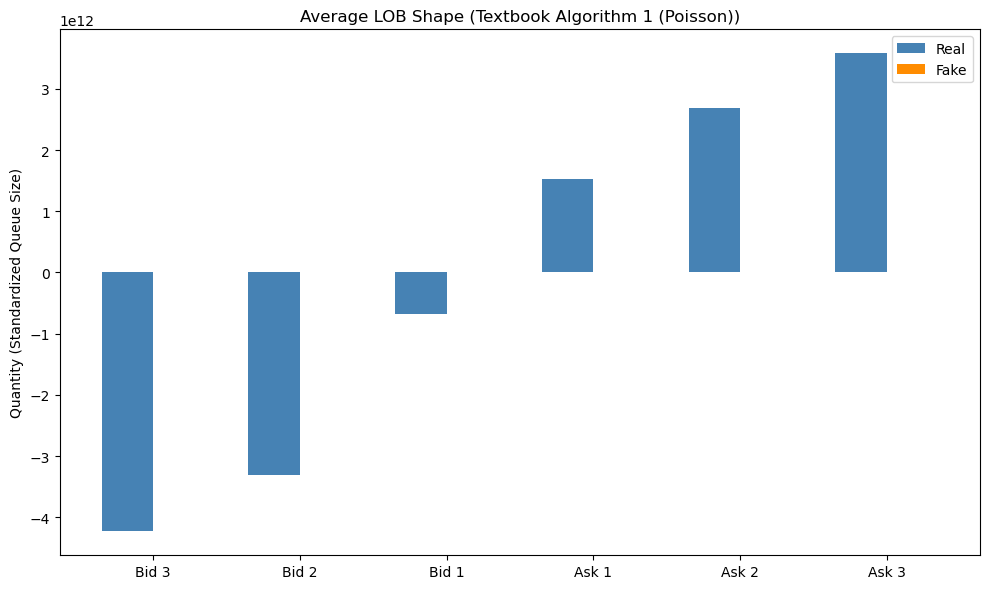

In [65]:
print("Generating plots...")
# Assuming real_X exists from your initial LOBSTER extraction
plot_benchmark(real_X, sim_poisson_norm, "Algorithm 1 (Poisson)")

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

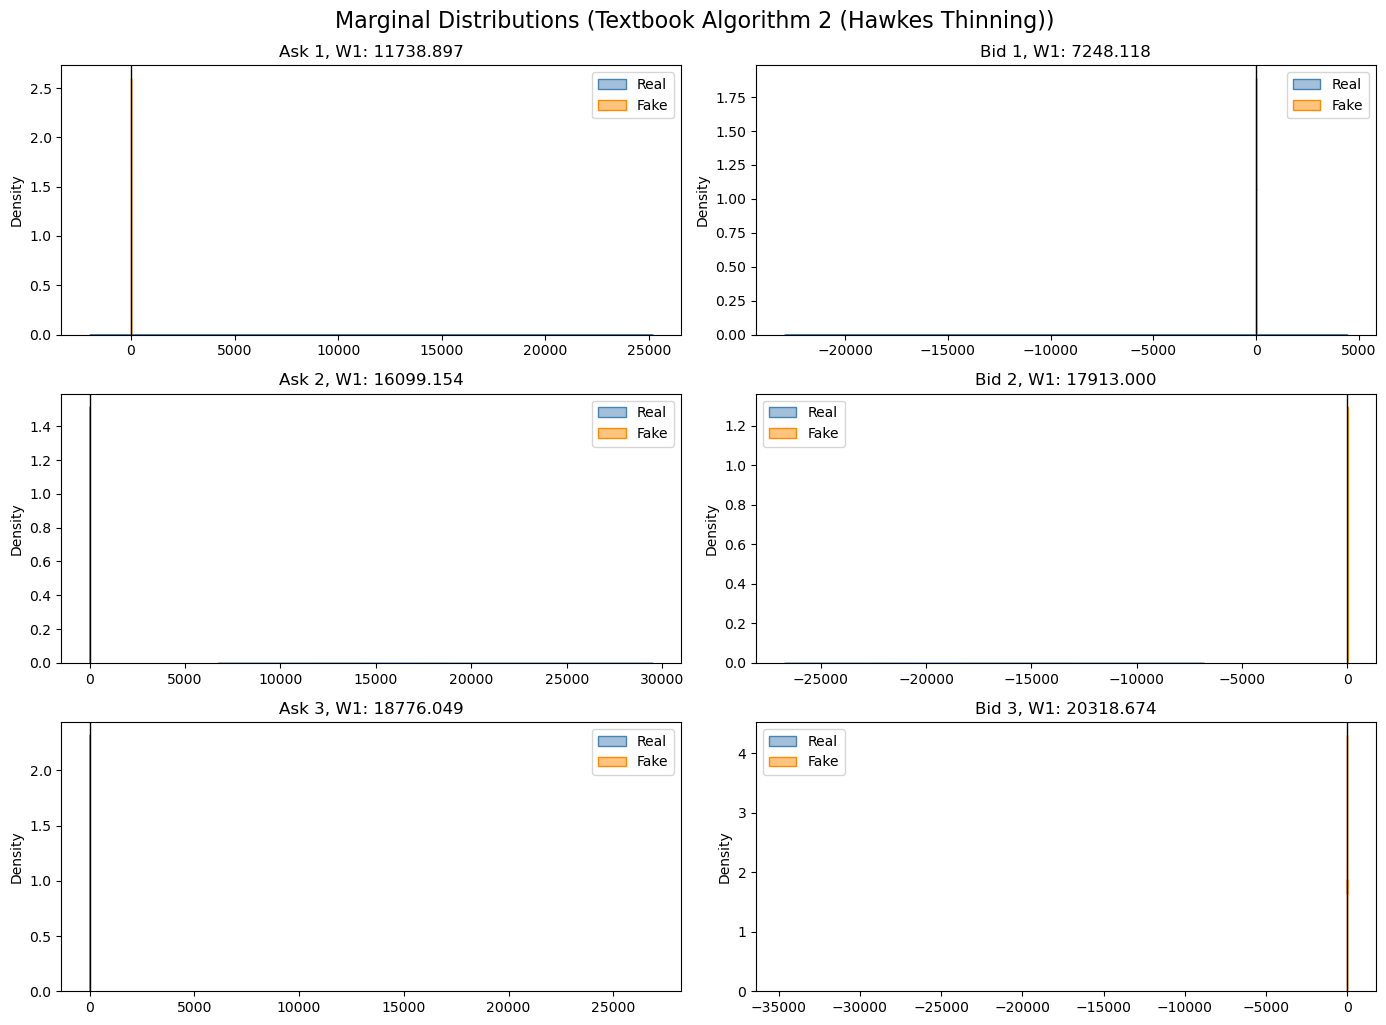

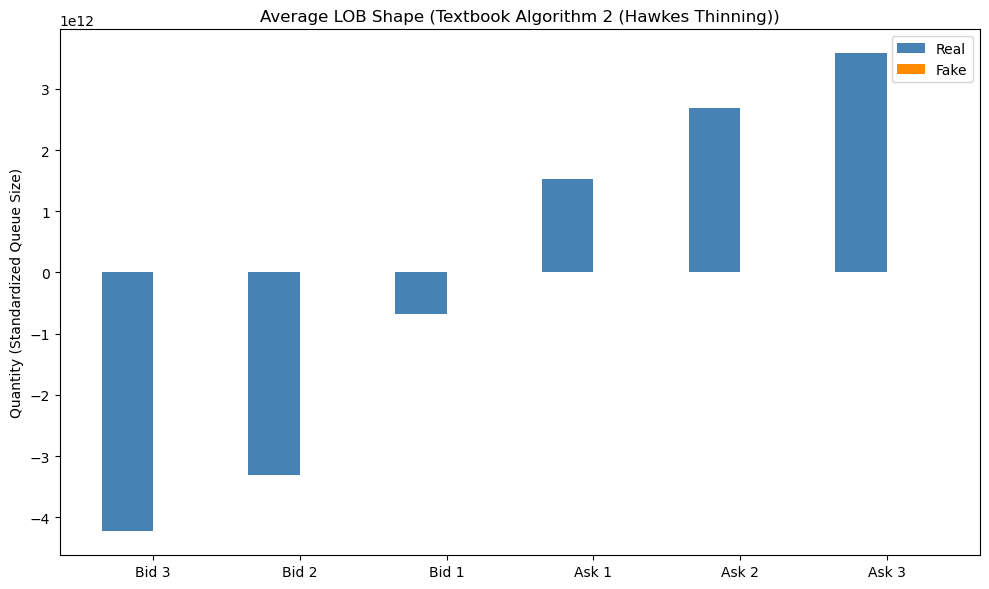

In [67]:
plot_benchmark(real_X, sim_hawkes_norm, "Algorithm 2 (Hawkes Thinning)")